# ABC Tech: Machine Learning for ITSM (PM-PR-0012)

Improve incident management with ML on ~46k incident records.

| # | Business goal | Section |
|---|---------------|---------|
| 1 | Predict high-priority (P1/P2) tickets | 2 |
| 2 | Forecast incident volume (quarterly / annual) | 3 |
| 3 | Auto-tag tickets with priority and department | 4 |
| 4 | Predict RFC (request for change) and failure / reopen | 5 |

Run all cells top to bottom. Data: `data/dataset.csv` (semicolon separated).

In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from statsmodels.tsa.holtwinters import ExponentialSmoothing

DATA_PATH = Path("data/dataset.csv")
OUT = Path("reports"); OUT.mkdir(exist_ok=True)
RS = 42
pd.set_option("display.max_columns", 50); plt.rcParams["figure.dpi"] = 100

## 1. Load, clean and check data quality

In [16]:
raw = pd.read_csv(
    r"C:\Users\lokes\OneDrive\Desktop\ABC Tech project\dataset.csv",
    sep=";",
    dtype=str,
    keep_default_na=False
)

print(raw.shape)
raw.head(3)

(46606, 25)


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,Category,KB_number,Alert_Status,No_of_Reassignments,Open_Time,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,incident,KM0000553,closed,26,05-02-2012 13:32,,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,,
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,incident,KM0000611,closed,33,12-03-2012 15:44,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,,
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NA,0.517551335,request for information,KM0000339,closed,3,29-03-2012 12:36,,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,,,


In [17]:
def clean(raw):
    df = raw.copy()
    # dates are day-first: 05-02-2012 13:32
    for c in ["Open_Time", "Reopen_Time", "Resolved_Time", "Close_Time"]:
        df[c] = pd.to_datetime(df[c].replace("", np.nan), format="%d-%m-%Y %H:%M", errors="coerce")
    # Urgency has one "5 - Very Low"; Impact "NS" / Priority "NA" mean not set
    df["Urgency"] = df["Urgency"].str.extract(r"(\d)")[0]
    for c in ["Impact", "Urgency", "Priority"]:
        df[c] = pd.to_numeric(df[c].replace({"NS": np.nan, "NA": np.nan, "": np.nan}), errors="coerce")
    # blank count columns mean zero related records
    for c in ["No_of_Reassignments", "No_of_Related_Interactions", "No_of_Related_Incidents", "No_of_Related_Changes"]:
        df[c] = pd.to_numeric(df[c].replace("", np.nan), errors="coerce").fillna(0)
    for c in ["CI_Name", "CI_Cat", "CI_Subcat", "WBS", "Category", "Closure_Code"]:
        df[c] = df[c].replace("", "unknown")
    # Handle_Time_hrs in the file is corrupted (digit groups with commas), so rebuild it from timestamps
    df["handle_hours"] = (df["Close_Time"] - df["Open_Time"]).dt.total_seconds() / 3600
    # features known when the ticket is created
    df["open_dow"] = df["Open_Time"].dt.dayofweek
    df["open_hour"] = df["Open_Time"].dt.hour
    return df

df = clean(raw)
df[["Open_Time", "Close_Time", "handle_hours", "Impact", "Urgency", "Priority"]].describe(include="all").T

,count,mean,min,25%,50%,75%,max,std
Open_Time,46606,2013-12-24 09:48:58.681714688,2012-02-05 13:32:00,2013-11-07 12:29:00,2013-12-23 11:31:00,2014-02-07 15:16:30,2014-03-31 17:24:00,NaN
Close_Time,46606,2013-12-29 12:56:57.305497088,2013-10-01 06:45:00,2013-11-12 16:43:15,2013-12-31 08:43:00,2014-02-12 14:25:00,2014-03-31 22:47:00,NaN
handle_hours,46606.0,123.132951,0.0,1.266667,18.4,95.083333,15722.616667,452.794319
Impact,45226.0,4.223632,1.0,4.0,4.0,5.0,5.0,0.705474
Urgency,46606.0,4.189546,1.0,4.0,4.0,5.0,5.0,0.724745
Priority,45226.0,4.215805,1.0,4.0,4.0,5.0,5.0,0.705624


In [18]:
NA_TOKENS = {"", "NA", "NS", "#N/A", "?"}
quality = pd.DataFrame({
    "blank_or_NA_share": raw.apply(lambda s: s.isin(NA_TOKENS).mean()).round(3),
    "n_unique": raw.nunique(),
})
display(quality)

ids = raw.Incident_ID.str[2:].astype(int)
span = ids.max() - ids.min() + 1
print(f"Rows: {len(raw):,} | duplicate Incident_IDs: {raw.Incident_ID.duplicated().sum()} | full-row duplicates: {raw.duplicated().sum()}")
print(f"Incident_ID span {span:,} vs rows {len(raw):,}: {span-len(raw):,} IDs absent ({(span-len(raw))/span:.1%})")
print("Status:", raw.Status.value_counts().to_dict())
print(f"Open_Time range: {df.Open_Time.min()} -> {df.Open_Time.max()}")
print(f"Close_Time range: {df.Close_Time.min()} -> {df.Close_Time.max()}")
print(f"Tickets opened before 2013-09-01: {(df.Open_Time < '2013-09-01').sum():,} ({(df.Open_Time < '2013-09-01').mean():.1%})")

,blank_or_NA_share,n_unique
CI_Name,0.000,3019
CI_Cat,0.002,13
CI_Subcat,0.002,65
WBS,0.000,274
Incident_ID,0.000,46606
Status,0.000,2
Impact,0.030,6
Urgency,0.000,6
Priority,0.030,6
number_cnt,0.000,46606


Rows: 46,606 | duplicate Incident_IDs: 0 | full-row duplicates: 0
Incident_ID span 47,054 vs rows 46,606: 448 IDs absent (1.0%)
Status: {'Closed': 46597, 'Work in progress': 9}
Open_Time range: 2012-02-05 13:32:00 -> 2014-03-31 17:24:00
Close_Time range: 2013-10-01 06:45:00 -> 2014-03-31 22:47:00
Tickets opened before 2013-09-01: 293 (0.6%)


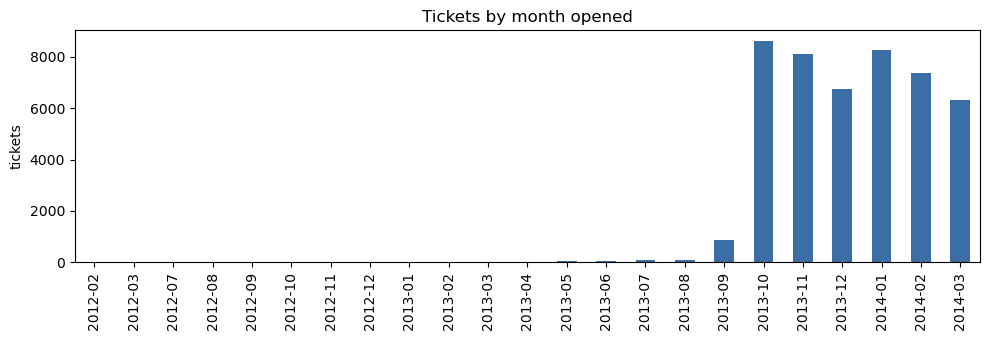

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.5))
df.Open_Time.dt.to_period("M").value_counts().sort_index().plot.bar(ax=ax, color="#3b6ea5")
ax.set_title("Tickets by month opened"); ax.set_xlabel(""); ax.set_ylabel("tickets")
plt.tight_layout(); plt.show()

**Data quality findings**

- Row count matches the brief (~46k) and there are no duplicates.
- Coverage is **not** 2012-2014 evenly. Almost every ticket was opened between **Oct 2013 and Mar 2014** (about 6 months); only a small tail of long-running tickets was opened earlier. All tickets have a Close_Time from Oct 2013 on, so the extract looks like "tickets closed in that window".
- This limits Task 2: there are only ~6 months of dense history, so seasonal monthly/annual forecasting is not statistically supported. The forecast below is daily and extrapolated, and should be treated as indicative.
- `Handle_Time_hrs` is corrupted in the file, so it is rebuilt from Open_Time and Close_Time.
- Weekends are almost empty (about 5 tickets a day), so this is a business-day log. The last days of the extract are also under-counted because tickets still open at extract time are missing.
- About 3% of tickets have no Impact/Priority (`NS` / `NA`). Related changes (1.2%), related incidents (2.6%) and reopens (4.9%) are rare.

### Priority matrix (rebuilt from the data, since the PDF table is garbled)

In [20]:
known = df.dropna(subset=["Impact", "Urgency", "Priority"])
matrix = known.groupby(["Impact", "Urgency"]).Priority.agg(lambda s: s.mode().iat[0]).unstack().astype("Int64")
display(matrix)
agree = known.Priority.eq(known.set_index(["Impact", "Urgency"]).index.map(matrix.stack().to_dict()).values).mean()
print(f"Priority is a fixed function of Impact x Urgency for {agree:.1%} of tickets that have all three.")
print("Priority counts:", df.Priority.value_counts().sort_index().to_dict())

Urgency,1,2,3,4,5
Impact,,,,,
1.0,1,<NA>,<NA>,<NA>,<NA>
2.0,<NA>,2,2,<NA>,<NA>
3.0,2,2,3,3,4
4.0,<NA>,3,3,4,4
5.0,3,3,4,4,5


Priority is a fixed function of Impact x Urgency for 100.0% of tickets that have all three.
Priority counts: {1.0: 3, 2.0: 697, 3.0: 5323, 4.0: 22717, 5.0: 16486}


In [21]:
CAT = ["CI_Name", "CI_Cat", "CI_Subcat", "WBS", "Category"]   # known at ticket creation
TIME = ["open_dow", "open_hour"]
RESULTS = []

def make_pipe(cat, num):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat),
        ("num", "passthrough", num),
    ])
    rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=3, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=RS)
    return Pipeline([("pre", pre), ("clf", rf)])

def run_binary(d, target, cat, num, name, cv=3):
    d = d.dropna(subset=[target])
    y = d[target].astype(int)
    X = d[cat + num].copy(); X[num] = X[num].fillna(0)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
    pipe = make_pipe(cat, num)
    # choose the decision threshold on out-of-fold training predictions (best F1), then test once
    oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    p, r, t = precision_recall_curve(y_tr, oof)
    thr = t[np.argmax((2 * p * r / (p + r + 1e-12))[:-1])]
    pipe.fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    res = dict(task=name, rows=len(d), positives=int(y.sum()), prevalence=round(y.mean(), 4),
               roc_auc=round(roc_auc_score(y_te, proba), 3), pr_auc=round(average_precision_score(y_te, proba), 3),
               threshold=round(float(thr), 3), precision=round(tp / max(tp + fp, 1), 3),
               recall=round(tp / max(tp + fn, 1), 3), f1=round(f1_score(y_te, pred), 3))
    RESULTS.append(res)
    print(pd.Series(res).to_string())
    print(f"Confusion matrix (test): TN={tn} FP={fp} FN={fn} TP={tp}")
    names = pipe[:-1].get_feature_names_out()
    imp = pd.Series(pipe[-1].feature_importances_, index=names).sort_values(ascending=False).head(10)
    pp, rr, _ = precision_recall_curve(y_te, proba)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(rr, pp); ax[0].axhline(y.mean(), ls="--", c="grey", label="no-skill")
    ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title(f"{name}: precision-recall (test)"); ax[0].legend()
    imp.iloc[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Top features")
    plt.tight_layout(); plt.show()
    return pipe, res

## 2. Task 1: predict high-priority tickets (P1/P2)

Priority is derived from Impact and Urgency, so those fields (and anything only known after the work starts, such as reassignments, times and closure code) are excluded. The model uses only information available when the ticket is opened. P1/P2 are rare, so the model is judged on precision-recall rather than accuracy.

P1/P2 tickets: 700 of 45226 (1.55%)
task          Task1 high priority
rows                        45226
positives                     700
prevalence                 0.0155
roc_auc                     0.946
pr_auc                      0.467
threshold                   0.641
precision                   0.458
recall                      0.707
f1                          0.556
Confusion matrix (test): TN=8789 FP=117 FN=41 TP=99


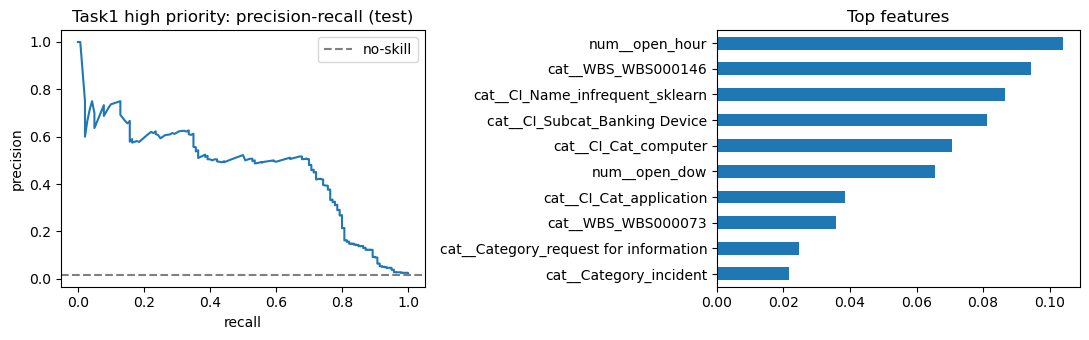

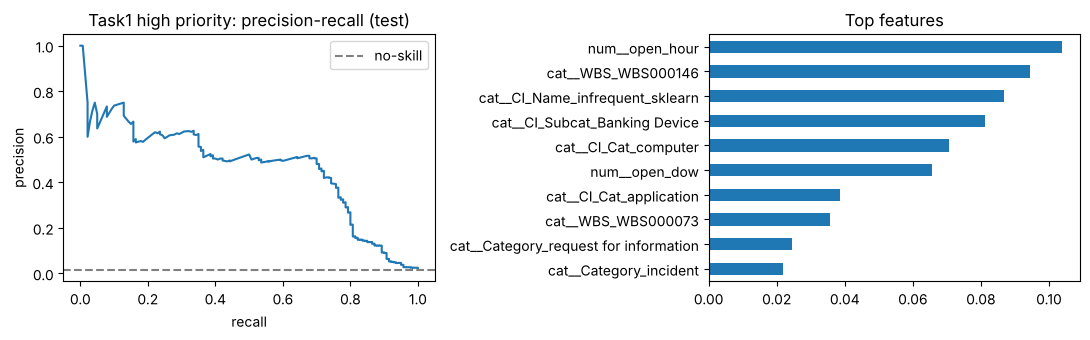

In [22]:
df["high_priority"] = np.where(df.Priority.isna(), np.nan, df.Priority.isin([1, 2]).astype(float))
print("P1/P2 tickets:", int(df.high_priority.sum()), "of", int(df.high_priority.notna().sum()), f"({df.high_priority.mean():.2%})")
pipe_t1, res_t1 = run_binary(df, "high_priority", CAT, TIME, "Task1 high priority")

## 3. Task 2: forecast incident volume

Only the dense window (tickets opened from 1 Oct 2013) is used. Two data behaviours shape the model:
- **Business days only**: weekends have almost no tickets, so the model uses weekly seasonality.
- **Under-counted tail**: tickets opened in the last days that were still open when the extract was taken are missing, which understates recent volume. The last 7 days are therefore dropped from fitting and treated as forecast.

A Holt-Winters model is compared with a seasonal-naive baseline on a 28-day hold-out. Quarterly and 12-month totals come from the daily forecast. With ~6 months of history these are indicative run-rate projections, not seasonal annual forecasts.

Fitting window: 2013-10-01 -> 2014-03-24 (175 days) | weekday mean 351/day
Last 8 days of the extract (incomplete): {'Mon 24-Mar': 341, 'Tue 25-Mar': 306, 'Wed 26-Mar': 292, 'Thu 27-Mar': 269, 'Fri 28-Mar': 205, 'Sat 29-Mar': 5, 'Sun 30-Mar': 3, 'Mon 31-Mar': 217}
Tickets taking > 3 days to close: 28.9% | > 7 days: 15.8%
Mean tickets by weekday (0=Mon): {0: 402.0, 1: 384.0, 2: 323.0, 3: 352.0, 4: 293.0, 5: 9.0, 6: 4.0}


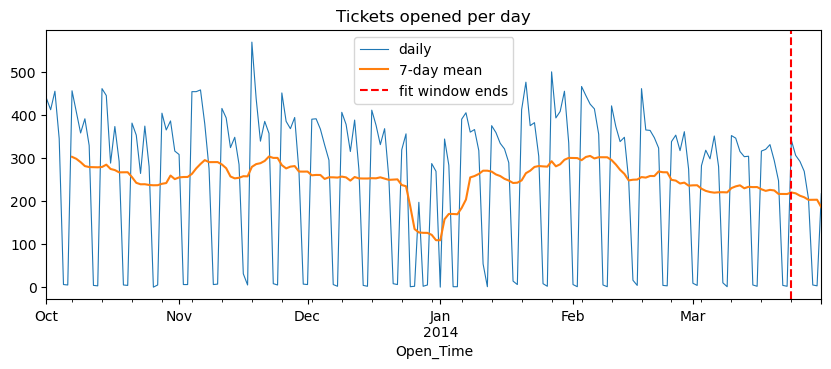

In [23]:
START = pd.Timestamp("2013-10-01"); OBS_END = pd.Timestamp("2014-03-24")
opened = df.loc[df.Open_Time >= START, "Open_Time"].dt.floor("D")
daily_all = opened.value_counts().sort_index().asfreq("D", fill_value=0)
daily = daily_all.loc[:OBS_END]
print(f"Fitting window: {daily.index.min().date()} -> {daily.index.max().date()} ({len(daily)} days) | weekday mean {daily[daily.index.dayofweek < 5].mean():.0f}/day")
print("Last 8 days of the extract (incomplete):", {d.strftime('%a %d-%b'): int(v) for d, v in daily_all.tail(8).items()})
print(f"Tickets taking > 3 days to close: {(df.handle_hours > 72).mean():.1%} | > 7 days: {(df.handle_hours > 168).mean():.1%}")
print("Mean tickets by weekday (0=Mon):", daily.groupby(daily.index.dayofweek).mean().round(0).to_dict())
fig, ax = plt.subplots(figsize=(10, 3.5)); daily_all.plot(ax=ax, lw=0.8, label="daily")
daily_all.rolling(7).mean().plot(ax=ax, label="7-day mean"); ax.axvline(OBS_END, ls="--", c="red", label="fit window ends")
ax.legend(); ax.set_title("Tickets opened per day"); plt.show()

,MAE all days (tickets/day),MAPE weekdays
Holt-Winters,25.611,0.109
Seasonal naive,47.625,0.214


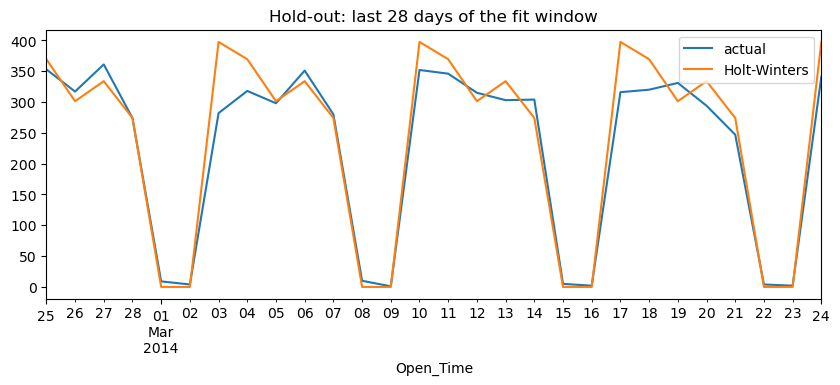

In [24]:
def hw(series):
    return ExponentialSmoothing(series, trend="add", damped_trend=True, seasonal="add",
                                seasonal_periods=7, initialization_method="estimated").fit()

H = 28
train, test = daily.iloc[:-H], daily.iloc[-H:]
pred = hw(train).forecast(H).clip(lower=0)
naive = np.tile(train.iloc[-28:].values.reshape(4, 7).mean(axis=0), 4)
wd = test.index.dayofweek < 5
mae = lambda a, b: float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
mape_wd = lambda a, b: float(np.mean(np.abs((np.asarray(a)[wd] - np.asarray(b)[wd]) / np.asarray(a)[wd])))
bt = pd.DataFrame({"MAE all days (tickets/day)": [mae(test, pred), mae(test, naive)],
                   "MAPE weekdays": [mape_wd(test, pred), mape_wd(test, naive)]},
                  index=["Holt-Winters", "Seasonal naive"]).round(3)
display(bt)
fig, ax = plt.subplots(figsize=(10, 3.5))
test.plot(ax=ax, label="actual"); pred.plot(ax=ax, label="Holt-Winters"); ax.legend(); ax.set_title("Hold-out: last 28 days of the fit window"); plt.show()

,observed,forecast,total
2013Q4,23477.0,0.0,23477.0
2014Q1,20682.0,1596.0,22278.0
2014Q2,0.0,20247.0,20247.0
2014Q3,0.0,19925.0,19925.0


,incidents
Observed 1 Oct 2013 - 24 Mar 2014,44159.0
Forecast 25 Mar - 30 Sep 2014,41768.0
12-month total (Oct-13 to Sep-14),85927.0


Average forecast weekday volume: 307/day vs 351/day observed


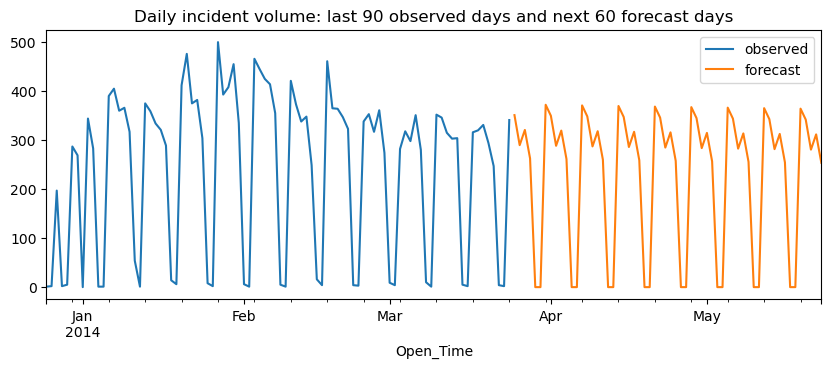

In [25]:
END = pd.Timestamp("2014-09-30")
horizon = (END - OBS_END).days
fc = hw(daily).forecast(horizon).clip(lower=0)      # 25 Mar 2014 -> 30 Sep 2014

def quarterly(actual, forecast):
    q = pd.concat([actual.resample("QS").sum().rename("observed"), forecast.resample("QS").sum().rename("forecast")], axis=1).fillna(0)
    q["total"] = q.sum(axis=1)
    q.index = q.index.to_period("Q").astype(str)
    return q

q_all = quarterly(daily, fc).round(0)
display(q_all)
window = pd.Series({"Observed 1 Oct 2013 - 24 Mar 2014": daily.sum(), "Forecast 25 Mar - 30 Sep 2014": fc.sum(),
                    "12-month total (Oct-13 to Sep-14)": daily.sum() + fc.sum()}).round(0)
display(window.to_frame("incidents"))
print(f"Average forecast weekday volume: {fc[fc.index.dayofweek < 5].mean():.0f}/day vs {daily[daily.index.dayofweek < 5].mean():.0f}/day observed")

fig, ax = plt.subplots(figsize=(10, 3.5))
daily.iloc[-90:].plot(ax=ax, label="observed"); fc.iloc[:60].plot(ax=ax, label="forecast"); ax.legend()
ax.set_title("Daily incident volume: last 90 observed days and next 60 forecast days"); plt.show()
q_all.to_csv(OUT / "task2_quarterly_forecast_total.csv"); fc.rename("forecast").to_csv(OUT / "task2_daily_forecast.csv")

In [26]:
# same forecast for the 5 biggest categories (CI_Cat)
top = df.loc[df.Open_Time >= START, "CI_Cat"].value_counts().head(5).index
rows = {}
for g in top:
    s = (df.loc[(df.Open_Time >= START) & (df.CI_Cat == g), "Open_Time"].dt.floor("D")
         .value_counts().sort_index().reindex(daily.index, fill_value=0))
    f = hw(s).forecast(horizon).clip(lower=0)
    q = quarterly(s, f)["total"]; q["12m_total"] = s.sum() + f.sum()
    rows[g] = q
by_cat = pd.DataFrame(rows).T.round(0)
display(by_cat)
by_cat.to_csv(OUT / "task2_forecast_by_category.csv")

,2013Q4,2014Q1,2014Q2,2014Q3,12m_total
application,16682.0,15479.0,14237.0,14481.0,60880.0
subapplication,3792.0,3894.0,3703.0,3764.0,15153.0
computer,1999.0,1623.0,1550.0,1578.0,6750.0
storage,327.0,380.0,376.0,381.0,1465.0
hardware,136.0,311.0,274.0,286.0,1007.0


## 4. Task 3: auto-tag priority and department

- **Priority**: Priority is a fixed lookup of Impact x Urgency (matrix above). When both are filled in, use the lookup. When they are not (or to pre-fill them), the model below predicts the priority tag from ticket context alone. P1 and P2 are merged because P1 has only 3 tickets.
- **Department**: the data has no assignment-group field, so the work breakdown structure (`WBS`) is used as the department proxy (WBS values below 200 tickets are grouped as OTHER). A CI_Name lookup rule is shown as the baseline to beat.

In [27]:
def run_multi(d, target, cat, num, name, topk=3):
    X = d[cat + num].copy(); X[num] = X[num].fillna(0)
    y = d[target].astype(str)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
    pipe = make_pipe(cat, num).fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te); classes = pipe.classes_
    top_idx = np.argsort(-proba, axis=1)[:, :topk]
    res = dict(task=name, rows=len(d), classes=len(classes), accuracy=round(accuracy_score(y_te, pred), 3),
               macro_f1=round(f1_score(y_te, pred, average="macro"), 3),
               majority_baseline=round(float((y_te == y_tr.value_counts().index[0]).mean()), 3),
               **{f"top{topk}_accuracy": round(float(np.mean([t in classes[r] for t, r in zip(y_te.values, top_idx)])), 3)})
    RESULTS.append(res)
    print(pd.Series(res).to_string())
    print(classification_report(y_te, pred, zero_division=0))
    return pipe, res, X_tr, X_te, y_tr, y_te

d3 = df.dropna(subset=["Priority"]).copy()
d3["priority_tag"] = d3.Priority.clip(lower=2).astype(int)   # 2 = P1/P2 combined
pipe_p, res_p, *_ = run_multi(d3, "priority_tag", CAT, TIME, "Task3 priority tag (context only)")

task                 Task3 priority tag (context only)
rows                                             45226
classes                                              4
accuracy                                         0.798
macro_f1                                         0.678
majority_baseline                                0.502
top3_accuracy                                    0.985
              precision    recall  f1-score   support

           2       0.28      0.71      0.40       140
           3       0.56      0.72      0.63      1065
           4       0.86      0.80      0.83      4544
           5       0.88      0.82      0.85      3297

    accuracy                           0.80      9046
   macro avg       0.64      0.77      0.68      9046
weighted avg       0.82      0.80      0.81      9046



In [28]:
vc = df.WBS.value_counts()
df["department"] = np.where(df.WBS.isin(vc[vc >= 200].index), df.WBS, "OTHER")
print("Department classes:", df.department.nunique(), "| largest share:", f"{df.department.value_counts(normalize=True).iloc[0]:.1%}")
CAT_R = ["CI_Name", "CI_Cat", "CI_Subcat", "Category"]
pipe_d, res_d, Xtr, Xte, ytr, yte = run_multi(df, "department", CAT_R, TIME, "Task3 department tag")

lookup = pd.concat([Xtr.CI_Name, ytr], axis=1).groupby("CI_Name")["department"].agg(lambda s: s.mode().iat[0])
rule = Xte.CI_Name.map(lookup).fillna(ytr.mode().iat[0])
print(f"CI_Name lookup-rule accuracy: {accuracy_score(yte, rule):.3f}  (model: {res_d['accuracy']})")

Department classes: 42 | largest share: 28.6%
task                 Task3 department tag
rows                                46606
classes                                42
accuracy                            0.921
macro_f1                            0.854
majority_baseline                   0.286
top3_accuracy                       0.988
              precision    recall  f1-score   support

       OTHER       0.95      0.81      0.88      1452
   WBS000013       1.00      1.00      1.00        55
   WBS000014       1.00      0.98      0.99        44
   WBS000015       0.67      0.93      0.78        41
   WBS000016       0.97      0.96      0.97       102
   WBS000023       0.92      0.97      0.94        60
   WBS000025       1.00      1.00      1.00        41
   WBS000043       0.75      0.93      0.83        46
   WBS000072       0.99      0.99      0.99       439
   WBS000073       1.00      0.99      0.99      2669
   WBS000088       0.99      1.00      1.00       124
   WBS00008

task                 Task3 department tag
rows                                46606
classes                                42
accuracy                            0.921
macro_f1                            0.855
majority_baseline                   0.286
top3_accuracy                       0.988
              precision    recall  f1-score   support

       OTHER       0.95      0.81      0.88      1452
   WBS000013       1.00      1.00      1.00        55
   WBS000014       1.00      0.98      0.99        44
   WBS000015       0.67      0.93      0.78        41
   WBS000016       0.97      0.96      0.97       102
   WBS000023       0.92      0.97      0.94        60
   WBS000025       1.00      1.00      1.00        41
   WBS000043       0.75      0.93      0.83        46
   WBS000072       1.00      0.99      0.99       439
   WBS000073       1.00      0.99      0.99      2669
   WBS000088       0.99      1.00      1.00       124
   WBS000089       0.57      0.54      0.55       121
   

CI_Name lookup-rule accuracy: 0.929  (model: 0.921)


## 5. Task 4: predict RFC and failure

No explicit labels exist, so two proxies are used (confirm with the business):
- **needs_rfc**: the incident has at least one related change.
- **failure (reopened)**: the incident was reopened after resolution, a signal of a failed fix or misconfiguration.

Both are rare, so PR-AUC against the base rate is the key number. Impact and Urgency are known at creation here, so they are allowed as features.

task          Task4 needs RFC
rows                    46606
positives                 560
prevalence              0.012
roc_auc                 0.872
pr_auc                  0.169
threshold               0.766
precision               0.184
recall                   0.25
f1                      0.212
Confusion matrix (test): TN=9086 FP=124 FN=84 TP=28


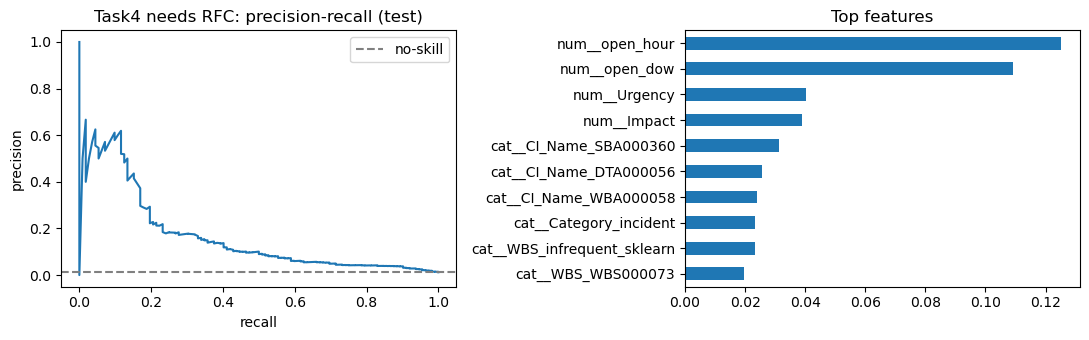

In [29]:
df["needs_rfc"] = (df.No_of_Related_Changes > 0).astype(int)
df["reopened"] = df.Reopen_Time.notna().astype(int)
NUM4 = TIME + ["Impact", "Urgency"]
pipe_rfc, res_rfc = run_binary(df, "needs_rfc", CAT, NUM4, "Task4 needs RFC")

task          Task4 reopened (failure proxy)
rows                                   46606
positives                               2284
prevalence                             0.049
roc_auc                                0.638
pr_auc                                 0.106
threshold                               0.61
precision                              0.137
recall                                 0.219
f1                                     0.169
Confusion matrix (test): TN=8236 FP=629 FN=357 TP=100


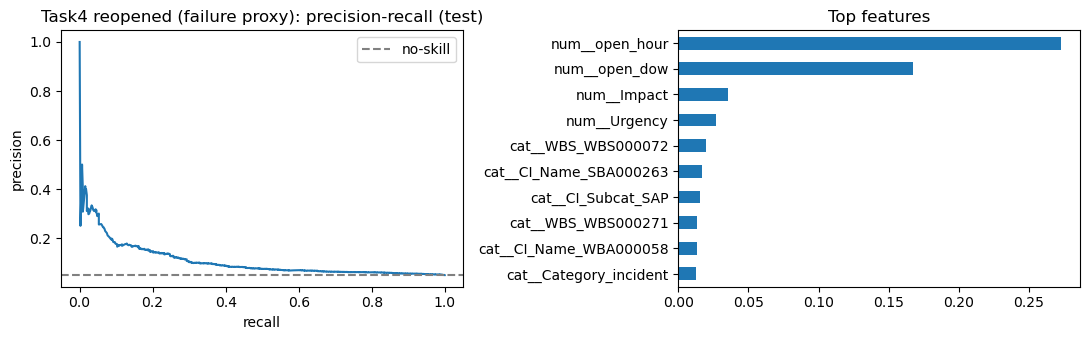

In [30]:
pipe_fail, res_fail = run_binary(df, "reopened", CAT, NUM4, "Task4 reopened (failure proxy)")

## 6. Summary

In [31]:
summary = pd.DataFrame(RESULTS)
display(summary.fillna(""))
summary.to_csv(OUT / "model_summary.csv", index=False)
print("Saved outputs to", OUT.resolve())

,task,rows,positives,prevalence,roc_auc,pr_auc,threshold,precision,recall,f1,classes,accuracy,macro_f1,majority_baseline,top3_accuracy
0,Task1 high priority,45226,700.0,0.0155,0.946,0.467,0.641,0.458,0.707,0.556,,,,,
1,Task3 priority tag (context only),45226,,,,,,,,,4.0,0.798,0.678,0.502,0.985
2,Task3 department tag,46606,,,,,,,,,42.0,0.921,0.854,0.286,0.988
3,Task4 needs RFC,46606,560.0,0.012,0.872,0.169,0.766,0.184,0.25,0.212,,,,,
4,Task4 reopened (failure proxy),46606,2284.0,0.049,0.638,0.106,0.61,0.137,0.219,0.169,,,,,


Saved outputs to C:\Users\lokes\OneDrive\Desktop\ABC Tech project\reports


## Caveats and next steps

1. **Coverage**: the data is essentially Oct 2013 - Mar 2014. Ask for the full 2012-2014 extract; seasonal and annual forecasts need at least two years.
2. **Labels**: department and failure are proxies. Request assignment group and configuration-failure fields if they exist.
3. **Evaluation**: a random split is used; with more history switch to a time-based split.
4. **Ideas**: gradient boosting, text features if ticket descriptions exist, probability calibration, cost-based thresholds.